# Automatic SIAM table and figures

This notebook reads `all_v1.xlsx`, keeps only matched runs available for every formulation, generates Table `tab:eilon-main-results`, and displays the publication figures inline. All figures use LaTeX fonts and are saved as PDF and PNG.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from plot_relaxation_gap_choices import (
    configure_fonts, paired_summary, paired_main_results,
    latex_main_results_table, matched_run_data,
    plot_performance_profile, plot_cumulative_solved_profile,
    plot_bar_all_sizes, final_mip_gap_summary,
    plot_average_unsolved_mip_gaps, plot_mip_gap_improvement,
)

WORKBOOK = ROOT / 'all_v1.xlsx'
FIGURES = ROOT / 'figures'
TABLES = ROOT / 'tables'
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)
configure_fonts('on')



## Automatic LaTeX table

All three measures are printed with one decimal. Boldface is selected using the unrounded averages.

In [2]:
main_results = paired_main_results(WORKBOOK, 'all_v1')
table_path = TABLES / 'eilon_main_results.tex'
latex = latex_main_results_table(main_results, table_path)
display(main_results)
print(latex)
print(f'Saved: {table_path}')
main_results[main_results['n'] == 40]

,n,tau,model,runs,runtime,gap_percent,unsolved_percent
0,10,1.5,compact,15,1.097913,0.004481,0.0
1,10,1.5,PW,15,0.886887,0.000045,0.0
2,10,1.5,LR-D,15,1.996884,0.000044,0.0
3,10,1.5,LR-A,15,1.911519,0.000046,0.0
4,10,1.5,LR-SA,15,1.368160,0.000045,0.0
...,...,...,...,...,...,...,...
70,50,3.0,compact,3,3600.000000,35.372266,100.0
71,50,3.0,PW,3,3600.000000,28.667180,100.0
72,50,3.0,LR-D,3,3600.000000,30.492980,100.0
73,50,3.0,LR-A,3,3600.000000,30.575083,100.0


\begin{table}[htbp]
\centering
\tiny
\setlength{\tabcolsep}{2.2pt}
\resizebox{\textwidth}{!}{%
\begin{tabular}{cc||rrrrr||rrrrr||rrrrr}
\hline\hline
& & \multicolumn{5}{c||}{Time (s)} & \multicolumn{5}{c||}{Opt Gap (\%)} & \multicolumn{5}{c}{Unsolved (\%)} \\
$n$ & $\tau$ & \ref{eq:weber_original} & \ref{mod:pairwise} & \ref{mod:mpco-disaggregated} & \ref{mod:mpco-aggregated} & \ref{mod:mpco-sum-aggregated} & \ref{eq:weber_original} & \ref{mod:pairwise} & \ref{mod:mpco-disaggregated} & \ref{mod:mpco-aggregated} & \ref{mod:mpco-sum-aggregated} & \ref{eq:weber_original} & \ref{mod:pairwise} & \ref{mod:mpco-disaggregated} & \ref{mod:mpco-aggregated} & \ref{mod:mpco-sum-aggregated} \\
\hline\hline
10 & $3/2$ & 1.1 & \textbf{0.9} & 2.0 & 1.9 & 1.4 & 0.0 & 0.0 & \textbf{0.0} & 0.0 & 0.0 & \textbf{0.0} & \textbf{0.0} & \textbf{0.0} & \textbf{0.0} & \textbf{0.0} \\
 & $2$ & \textbf{0.4} & 0.6 & 1.2 & 1.1 & 1.0 & 0.0 & 0.0 & \textbf{0.0} & 0.0 & 0.0 & \textbf{0.0} & \textbf{0.0} & \textbf{0.0} 

,n,tau,model,runs,runtime,gap_percent,unsolved_percent
45,40,1.5,compact,15,3600.000000,34.843149,100.000000
46,40,1.5,PW,15,3557.998958,23.079887,93.333333
47,40,1.5,LR-D,15,3553.068804,23.002565,93.333333
48,40,1.5,LR-A,15,3598.536887,22.930593,93.333333
49,40,1.5,LR-SA,15,3600.000000,26.636689,100.000000
50,40,2.0,compact,15,3600.000000,33.303793,100.000000
51,40,2.0,PW,15,3600.000000,24.789015,100.000000
52,40,2.0,LR-D,15,3600.000000,24.963543,100.000000
53,40,2.0,LR-A,15,3600.000000,25.003945,100.000000
54,40,2.0,LR-SA,15,3600.000000,27.894088,100.000000


## Performance profile

Unsuccessful runs receive an infinite performance ratio and remain in the denominator. The profile includes all tested sizes.

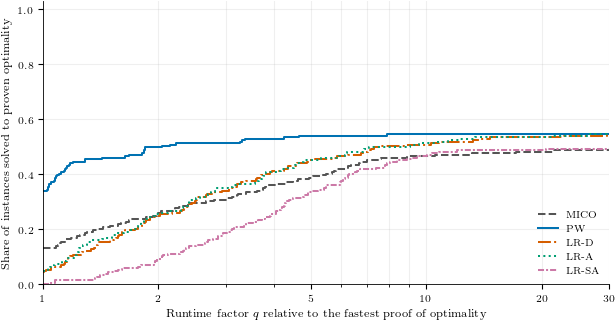

In [3]:
matched = matched_run_data(WORKBOOK, 'all_v1')
fig = plot_performance_profile(matched, sizes=(10, 20, 30, 40, 50), log_scale=True)
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'performance_profile.{extension}', dpi=300)
plt.show()
plt.close(fig)

## Cumulative solved-instances profile

This profile shows the number of matched instances certified by each method within a given CPU-time limit. The CPU-time axis is logarithmic so that both short and long runs remain visible.

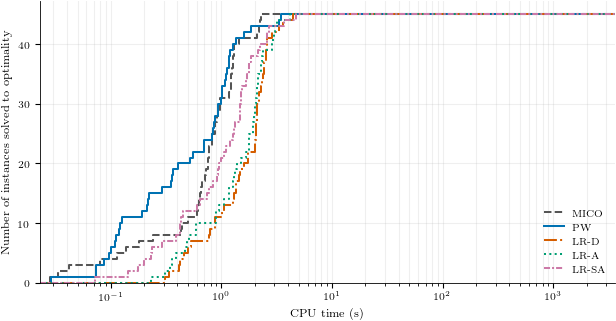

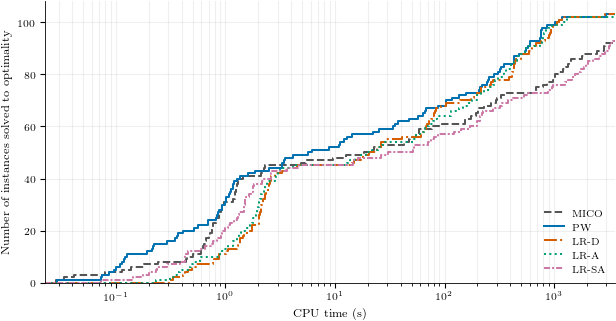

In [4]:
fig = plot_cumulative_solved_profile(
    matched, sizes=(10,), time_limit=3600, log_scale=True
)
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'cumulative_solved_profile_10.{extension}', dpi=300)
plt.show()
plt.close(fig)

fig = plot_cumulative_solved_profile(
    matched, sizes=(10, 20, 30, 40, 50), time_limit=3600, log_scale=True
)
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'cumulative_solved_profile.{extension}', dpi=300)
plt.show()
plt.close(fig)

## Percentage solved within a given CPU time

This absolute-time profile complements the relative performance profile. For each method and CPU-time threshold, it reports the percentage of matched instances for which global optimality has been certified. Runs without a proof of optimality remain in the denominator.

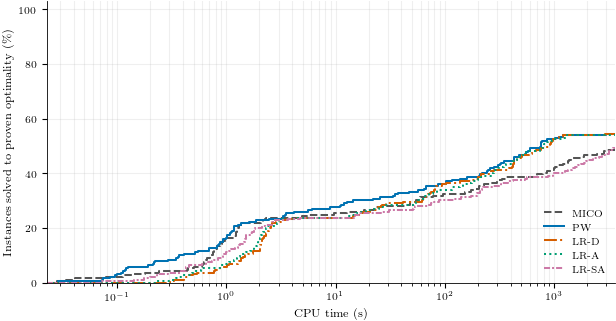

In [5]:
profile_models = ['compact', 'PW', 'LR-D', 'LR-A', 'LR-SA']
profile_labels = {'compact': 'MICO', 'PW': 'PW', 'LR-D': 'LR-D',
                  'LR-A': 'LR-A', 'LR-SA': 'LR-SA'}
profile_colors = {'compact': '#555555', 'PW': '#0072B2', 'LR-D': '#D55E00',
                  'LR-A': '#009E73', 'LR-SA': '#CC79A7'}
profile_styles = ['--', '-', '-.', ':', (0, (3, 1, 1, 1))]
profile_data = matched[matched['n'].isin((10, 20, 30, 40, 50))].copy()
profile_data['runtime'] = pd.to_numeric(profile_data['runtime'], errors='coerce').clip(upper=3600)
positive_times = profile_data.loc[profile_data['certified'] & profile_data['runtime'].gt(0), 'runtime']
minimum_time = max(1e-3, 0.8 * positive_times.min()) if not positive_times.empty else 1e-3
event_times = profile_data.loc[profile_data['certified'], 'runtime'].dropna().to_numpy(float)
time_grid = np.unique(np.r_[minimum_time, event_times, 3600.0])
time_grid = time_grid[(time_grid >= minimum_time) & (time_grid <= 3600.0)]

fig, ax = plt.subplots(figsize=(6.2, 3.25))
for model, linestyle in zip(profile_models, profile_styles):
    method_data = profile_data[profile_data['configuration'].eq(model)]
    certified_times = method_data.loc[method_data['certified'], 'runtime'].to_numpy(float)
    solved_percent = 100.0 * np.array([(certified_times <= t).sum() for t in time_grid]) / len(method_data)
    ax.step(time_grid, solved_percent, where='post', color=profile_colors[model],
            linewidth=1.45, linestyle=linestyle, label=profile_labels[model])
ax.set_xscale('log')
ax.set_xlim(minimum_time, 3600)
ax.set_ylim(0, 103)
ax.set_xlabel('CPU time (s)')
ax.set_ylabel(r'Instances solved to proven optimality (\%)')
ax.legend(frameon=False, fontsize=7.2, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.2, which='both')
fig.tight_layout(pad=0.3)
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'cumulative_solved_percent_profile.{extension}', dpi=300)
plt.show()
plt.close(fig)

## Cuts and time spent in SDP subproblems

The next summary uses the same matched cases as the main comparisons and excludes MICO, which is not a projector formulation. `projection_logic_cuts` records the optimality or logic cuts generated by the decomposition. `partition_triangle_cuts` records the projector inequalities separated from the partition structure. `sdp_bound_time` is reported as the time spent computing SDP bounds when that field is available. The table reports averages by size, norm, and projector method.

,n,tau,configuration,runs,average_logic_cuts,average_triangle_cuts,average_total_cuts,average_sdp_time,median_sdp_time,average_sdp_time_share
0,10,1.5,LR-A,15,1.4,26.0,27.4,1.0,1.0,56.8
1,10,1.5,LR-D,15,1.4,28.6,30.0,1.1,0.9,57.9
2,10,1.5,LR-SA,15,1.5,39.5,41.0,0.2,0.2,20.0
3,10,1.5,PW,15,1.4,24.2,25.6,0.0,0.0,7.7
4,10,2.0,LR-A,15,1.5,26.3,27.7,0.6,0.5,63.1
5,10,2.0,LR-D,15,1.5,26.2,27.7,0.6,0.4,62.3
6,10,2.0,LR-SA,15,1.6,37.7,39.3,0.1,0.1,24.0
7,10,2.0,PW,15,1.5,24.7,26.1,0.0,0.0,20.0
8,10,3.0,LR-A,15,1.2,27.3,28.5,1.0,1.1,55.3
9,10,3.0,LR-D,15,1.2,28.2,29.4,1.2,1.2,59.5


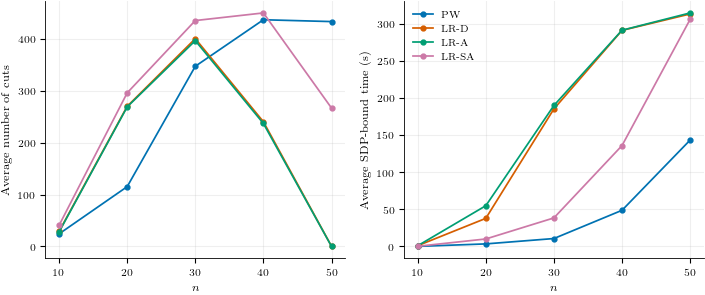

In [11]:
projector_models = ['PW', 'LR-D', 'LR-A', 'LR-SA']
diagnostic_columns = ['projection_logic_cuts', 'partition_triangle_cuts', 'sdp_bound_time']
missing_diagnostics = [column for column in diagnostic_columns if column not in matched.columns]
if missing_diagnostics:
    raise ValueError(f'Missing diagnostic columns: {missing_diagnostics}')

projector_runs = matched[matched['configuration'].isin(projector_models)].copy()
for column in diagnostic_columns + ['runtime']:
    projector_runs[column] = pd.to_numeric(projector_runs[column], errors='coerce')
projector_runs['total_cuts'] = (projector_runs['projection_logic_cuts'].fillna(0)
                                  + projector_runs['partition_triangle_cuts'].fillna(0))
projector_runs['sdp_time_share_percent'] = np.where(
    projector_runs['runtime'].gt(0),
    100.0 * projector_runs['sdp_bound_time'] / projector_runs['runtime'],
    np.nan,
)

cut_sdp_summary = (
    projector_runs.groupby(['n', 'tau', 'configuration'], as_index=False)
    .agg(
        runs=('instance', 'size'),
        average_logic_cuts=('projection_logic_cuts', 'mean'),
        average_triangle_cuts=('partition_triangle_cuts', 'mean'),
        average_total_cuts=('total_cuts', 'mean'),
        average_sdp_time=('sdp_bound_time', 'mean'),
        median_sdp_time=('sdp_bound_time', 'median'),
        average_sdp_time_share=('sdp_time_share_percent', 'mean'),
    )
)
display(cut_sdp_summary.round({
    'average_logic_cuts': 1, 'average_triangle_cuts': 1,
    'average_total_cuts': 1, 'average_sdp_time': 1,
    'median_sdp_time': 1, 'average_sdp_time_share': 1,
}))

diagnostics_by_size = (
    projector_runs.groupby(['n', 'configuration'], as_index=False)
    .agg(average_total_cuts=('total_cuts', 'mean'),
         average_sdp_time=('sdp_bound_time', 'mean'))
)
fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.0))
for model in projector_models:
    part = diagnostics_by_size[diagnostics_by_size['configuration'].eq(model)]
    axes[0].plot(part['n'], part['average_total_cuts'], marker='o',
                 linewidth=1.25, markersize=3.5, color=profile_colors[model],
                 label=profile_labels[model])
    axes[1].plot(part['n'], part['average_sdp_time'], marker='o',
                 linewidth=1.25, markersize=3.5, color=profile_colors[model],
                 label=profile_labels[model])
axes[0].set_yscale('linear')
axes[0].set_xlabel(r'$n$')
axes[0].set_ylabel('Average number of cuts')
axes[1].set_xlabel(r'$n$')
axes[1].set_ylabel('Average SDP-bound time (s)')
for ax in axes:
    ax.set_xticks(sorted(diagnostics_by_size['n'].unique()))
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.2, which='both')
axes[1].legend(frameon=False, fontsize=7.2)
fig.tight_layout(pad=0.35, w_pad=1.2)
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'projector_cuts_and_sdp_time.{extension}', dpi=300)
plt.show()
plt.close(fig)

## Relaxation-gap bars for every size and norm

The outer blocks correspond to $n\in\{10,20,30,40,50\}$. Each outer block has three $\tau$ subblocks, and each subblock has four projector-method bars. Negative values indicate an improvement over MISOCO. Combinations not yet available for all five methods are labeled `N/A`.

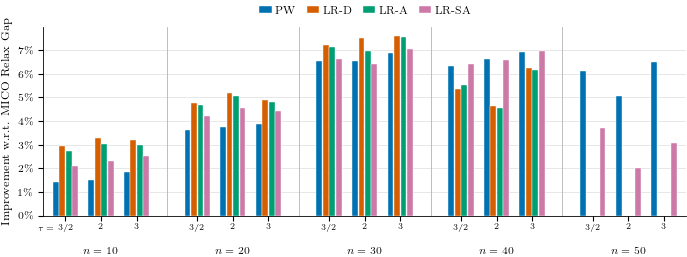

In [7]:
relaxation_summary = paired_summary(WORKBOOK, 'all_v1')
fig = plot_bar_all_sizes(relaxation_summary, sizes=(10, 20, 30, 40, 50))
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'relaxation_gap_bar_all_sizes.{extension}', dpi=300)
plt.show()
plt.close(fig)

## Final MIP gaps on difficult instances

The following plot uses the common matched instances for which at least one method did not prove optimality. Every method is therefore averaged over exactly the same instances within each $(n,\tau)$ group. The bars report the average final solver MIP gap in percent.

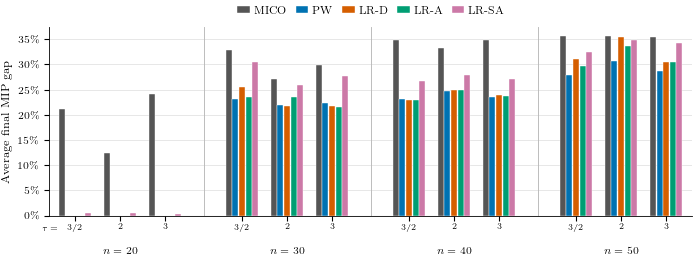

In [8]:
difficult_gap_summary = final_mip_gap_summary(
    WORKBOOK, 'all_v1', selection='any_unsolved'
)
fig = plot_average_unsolved_mip_gaps(
    difficult_gap_summary, sizes=(20, 30, 40, 50)
)
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'average_final_mip_gap_difficult.{extension}', dpi=300)
plt.show()
plt.close(fig)

## Final MIP-gap improvement over MISOCO

This second view retains the common matched instances for which MISOCO did not prove optimality. For each projector method, a positive bar is the percentage reduction in its average final MIP gap relative to the average MISOCO gap. A negative bar indicates a larger average gap than MISOCO.

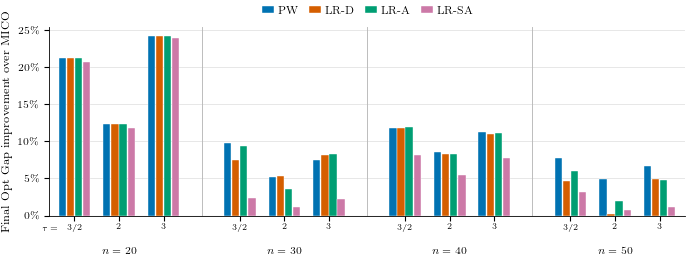

In [9]:
misoco_unsolved_gap_summary = final_mip_gap_summary(
    WORKBOOK, 'all_v1', selection='any_unsolved'
)
fig = plot_mip_gap_improvement(
    misoco_unsolved_gap_summary, sizes=(20, 30, 40, 50)
)
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'mip_gap_improvement_over_misoco.{extension}', dpi=300)
plt.show()
plt.close(fig)

In [10]:
main_results

,n,tau,model,runs,runtime,gap_percent,unsolved_percent
0,10,1.5,compact,15,1.097913,0.004481,0.0
1,10,1.5,PW,15,0.886887,0.000045,0.0
2,10,1.5,LR-D,15,1.996884,0.000044,0.0
3,10,1.5,LR-A,15,1.911519,0.000046,0.0
4,10,1.5,LR-SA,15,1.368160,0.000045,0.0
...,...,...,...,...,...,...,...
70,50,3.0,compact,3,3600.000000,35.372266,100.0
71,50,3.0,PW,3,3600.000000,28.667180,100.0
72,50,3.0,LR-D,3,3600.000000,30.492980,100.0
73,50,3.0,LR-A,3,3600.000000,30.575083,100.0
